In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/train_features.parquet
/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/test_features.parquet
/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/test_features_location_scale.parquet
/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/test_features_location.parquet
/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/train_features_location.parquet
/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/train_features_location_scale.parquet


# imputation

## hàm tính toán

In [2]:
def interpolate_single_hand(series: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Nội suy tuyến tính cho một bàn tay.
    Input:
        - series: Mảng tọa độ RAW của 1 tay, kích thước (T, 63)
    Output:
        - interpolated: Mảng tọa độ đã điền khuyết, kích thước (T, 63)
        - flag: Cờ báo nội suy, kích thước (T,) mang giá trị 1 (Imputed) hoặc 0 (Real)
    """
    series = np.asarray(series, dtype=np.float32)
    T, num_features = series.shape
    
    interpolated = series.copy()
    flag = np.zeros(T, dtype=np.int8) # Cờ 1 chiều, giá trị 0 hoặc 1

    # Tìm index của các frame hợp lệ (tay được nhận diện)
    valid_idx = np.where(np.any(series != 0, axis=1))[0]

    # Nếu cả video không có bàn tay nào, trả về nguyên trạng
    if len(valid_idx) == 0:
        return interpolated, flag

    # Lấy giới hạn đầu và cuối
    first_valid = valid_idx[0]
    last_valid = valid_idx[-1]

    # Trục thời gian tổng (0, 1, 2, ..., T-1)
    x_all = np.arange(T)

    # 1. Bật cờ (Flag) cho những frame nằm GIỮA điểm đầu và điểm cuối bị khuyết
    missing_mask = np.all(series == 0, axis=1)
    # Chỉ đánh dấu cờ những chỗ nằm trong khoảng có thể nội suy
    impute_condition = missing_mask & (x_all > first_valid) & (x_all < last_valid)
    flag[impute_condition] = 1

    # 2. Nội suy siêu tốc bằng np.interp cho từng cột (x, y, z)
    for col in range(num_features):
        y_valid = series[valid_idx, col]
        interpolated[:, col] = np.interp(x_all, valid_idx, y_valid)

    # 3. Ép vùng không thể nội suy (đầu và cuối video) về lại giá trị 0
    interpolated[:first_valid] = 0.0
    interpolated[last_valid + 1:] = 0.0

    return interpolated.astype(np.float32), flag

In [3]:
def apply_imputation_to_both_hands(
    left_series: np.ndarray, 
    right_series: np.ndarray
) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    """
    Hàm tiện ích để xử lý cùng lúc 2 tay.
    Input:
        - left_series, right_series: kích thước (T, 63)
    Output:
        - Trả về tọa độ nội suy và cờ của từng tay.
    """
    left_filled, left_flag = interpolate_single_hand(left_series)
    right_filled, right_flag = interpolate_single_hand(right_series)
    
    return left_filled, right_filled, left_flag, right_flag

## chạy với data

In [4]:
from tqdm import tqdm

In [5]:
def apply_imputation_to_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    """
    Hàm bọc (Wrapper) để áp dụng nội suy cho toàn bộ Dataset.
    Tự động nhóm theo video và xử lý cho cả tay trái, tay phải và các đặc trưng chéo (cross).
    """
    # 1. Tự động tìm tên các cột đặc trưng
    left_cols = [c for c in df.columns if c.startswith('left_norm_') or c.startswith('left_bone_') or c.startswith('left_dist_')]
    right_cols = [c for c in df.columns if c.startswith('right_norm_') or c.startswith('right_bone_') or c.startswith('right_dist_')]
    cross_cols = [c for c in df.columns if c.startswith('cross_')]
    
    # 2. BẮT BUỘC: Sắp xếp theo video và thứ tự thời gian (frame_index)
    df = df.sort_values(by=['video_name', 'frame_index']).reset_index(drop=True)
    
    # Khởi tạo sẵn cột cờ báo nội suy (Imputation flag)
    df['left_imputed_flag'] = 0
    df['right_imputed_flag'] = 0
    
    print(f"Bắt đầu xử lý nội suy cho {len(df['video_name'].unique())} videos...")
    
    # 3. Duyệt qua TỪNG VIDEO để nội suy (tránh nội suy vắt chéo giữa các video)
    for video_name, group in tqdm(df.groupby('video_name')):
        idx = group.index
        
        # Rút trích mảng dữ liệu của 2 tay
        left_series = group[left_cols].values
        right_series = group[right_cols].values
        
        # Chạy qua siêu hàm nội suy của bạn
        left_filled, right_filled, left_flag, right_flag = apply_imputation_to_both_hands(left_series, right_series)
        
        # ĐẶC BIỆT: Phải nội suy cả khối đặc trưng liên tay (cross-hand)
        # Vì nếu mất dấu 1 tay, khoảng cách cross cũng đang bị gán bằng 0
        cross_series = group[cross_cols].values
        cross_filled, _ = interpolate_single_hand(cross_series)
        
        # 4. Ghi đè dữ liệu đã nội suy trở lại DataFrame gốc
        df.loc[idx, left_cols] = left_filled
        df.loc[idx, right_cols] = right_filled
        df.loc[idx, cross_cols] = cross_filled
        df.loc[idx, 'left_imputed_flag'] = left_flag
        df.loc[idx, 'right_imputed_flag'] = right_flag
        
    return df

In [6]:
TRAIN_PATH = "/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/train_features_location.parquet"
TEST_PATH = "/kaggle/input/datasets/binhdanghai/metc-dataset-preprocessed-features/test_features_location.parquet"

train_out = "/kaggle/working/train_imputation_location.parquet"
test_out = "/kaggle/working/test_imputation_location.parquet"

In [7]:
print("--- ĐANG XỬ LÝ TẬP TRAIN ---")
train_df = pd.read_parquet(TRAIN_PATH)
train_imputed_df = apply_imputation_to_dataframe(train_df)

print("\n--- ĐANG XỬ LÝ TẬP TEST ---")
test_df = pd.read_parquet(TEST_PATH)
test_imputed_df = apply_imputation_to_dataframe(test_df)

train_imputed_df.to_parquet(train_out, index=False)
test_imputed_df.to_parquet(test_out, index=False)

print(f"\nHoàn tất! Dữ liệu cuối cùng đã được lưu tại:")
print(f" - {train_out}")
print(f" - {test_out}")

--- ĐANG XỬ LÝ TẬP TRAIN ---
Bắt đầu xử lý nội suy cho 169 videos...


100%|██████████| 169/169 [00:30<00:00,  5.62it/s]



--- ĐANG XỬ LÝ TẬP TEST ---
Bắt đầu xử lý nội suy cho 42 videos...


100%|██████████| 42/42 [00:03<00:00, 12.41it/s]



Hoàn tất! Dữ liệu cuối cùng đã được lưu tại:
 - /kaggle/working/train_imputation_location.parquet
 - /kaggle/working/test_imputation_location.parquet


# Xây dựng chuỗi chuyển động (Sequence Construction)

In [8]:
from sklearn.preprocessing import StandardScaler

## lớp tạo sequence

In [9]:
class SlidingWindowBuilder:
    """Tạo sequence windows dạng fixed-length cho LSTM/GRU/1D CNN."""

    def __init__(self, window_size: int = 30, stride: int = 1):
        self.window_size = window_size
        self.stride = stride

    def build_windows(self, feature_sequence: np.ndarray, labels: np.ndarray):
        """feature_sequence: (T, F)
        labels: (T,) hoặc (T, 1)
        """
        feature_sequence = np.asarray(feature_sequence, dtype=np.float32)
        labels = np.asarray(labels).reshape(-1)

        if len(feature_sequence) != len(labels):
            raise ValueError("Số frame và số label phải bằng nhau")

        windows = []
        window_labels = []

        for start in range(0, len(feature_sequence) - self.window_size + 1, self.stride):
            end = start + self.window_size
            seq = feature_sequence[start:end]
            label = labels[end - 1]   # Gán nhãn của khung hình cuối cùng

            # SỬA Ở ĐÂY: Kiểm tra TẤT CẢ các frame trong cửa sổ
            # np.any(seq != 0, axis=1): Trả về mảng (window_size,) True/False xem từng frame có dữ liệu không
            # np.all(...): Bắt buộc TẤT CẢ các frame đều phải trả về True
            if not np.all(np.any(seq != 0, axis=1)):
                continue

            windows.append(seq)
            window_labels.append(label)

        return np.array(windows, dtype=np.float32), np.array(window_labels, dtype=np.int64)

    def fit_transform_with_scaler(self, X_train: np.ndarray, X_valid=None):
        """Chuẩn hóa StandardScaler dựa trên tập train."""
        X_train_2d = X_train.reshape(-1, X_train.shape[-1])
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train_2d).reshape(X_train.shape)

        if X_valid is not None:
            X_valid_2d = X_valid.reshape(-1, X_valid.shape[-1])
            X_valid_scaled = scaler.transform(X_valid_2d).reshape(X_valid.shape)
            return X_train_scaled, X_valid_scaled, scaler

        return X_train_scaled, scaler

In [10]:
# Khai báo các cột không phải là đặc trưng (Metadata)
META_COLS = [
    "video_name", "frame_index", "timestamp", "motion_label",
    "left_hand_detected", "right_hand_detected",
    "left_hand_confidence", "right_hand_confidence",
    "left_imputed_flag", "right_imputed_flag"
]

In [11]:
def create_3d_dataset(df: pd.DataFrame, builder: SlidingWindowBuilder):
    """
    Duyệt qua từng video, cắt cửa sổ trượt và gộp lại thành ma trận 3D.
    """
    all_windows = []
    all_labels = []
    
    # Lọc lấy danh sách các cột đặc trưng (những cột không nằm trong META_COLS)
    feature_cols = [c for c in df.columns if c not in META_COLS]
    
    print(f"Bắt đầu cắt Sequence (Window Size = {builder.window_size})...")
    # Groupby để đảm bảo cửa sổ không bị vắt chéo giữa 2 video khác nhau
    for video_name, group in tqdm(df.groupby('video_name')):
        # Bắt buộc sort theo thời gian để cửa sổ đi theo đúng chiều xuôi
        group = group.sort_values('frame_index')
        
        features = group[feature_cols].values
        labels = group['motion_label'].values
        
        # Gọi class SlidingWindowBuilder của bạn
        windows, window_labels = builder.build_windows(features, labels)
        
        # Nếu video đủ dài và trích xuất được cửa sổ, thì thêm vào mảng tổng
        if len(windows) > 0:
            all_windows.append(windows)
            all_labels.append(window_labels)
            
    # Nối tất cả các mảng của các video lại với nhau theo trục 0 (số lượng mẫu)
    X = np.concatenate(all_windows, axis=0)
    y = np.concatenate(all_labels, axis=0)
    
    return X, y

## chạy với data

In [12]:
print("1. Đang đọc dữ liệu - mode raw...")
train_df = pd.read_parquet("/kaggle/working/train_imputation_location.parquet")
test_df = pd.read_parquet("/kaggle/working/test_imputation_location.parquet")

# 2. Khởi tạo Builder (Ví dụ: Thí nghiệm cho LSTM với window_size = 30 hoặc 15)
# Nếu bạn muốn train GRU hay CNN, chỉ cần đổi số này thành 24 hoặc 48
# stride = 2 => trượt 2 frame 1 lần
builder = SlidingWindowBuilder(window_size=48, stride=2)

print("\n2. Xử lý tập TRAIN")
X_train_raw, y_train = create_3d_dataset(train_df, builder)

print("\n3. Xử lý tập TEST")
X_test_raw, y_test = create_3d_dataset(test_df, builder)

print(f"\nKích thước X_train trước chuẩn hóa: {X_train_raw.shape}")
print(f"Kích thước X_test trước chuẩn hóa: {X_test_raw.shape}")

# 4. Chuẩn hóa bằng hàm siêu xịn của bạn (fit_transform)
print("\n4. Đang chuẩn hóa StandardScaler...")
X_train_scaled, X_test_scaled, scaler = builder.fit_transform_with_scaler(X_train_raw, X_test_raw)

print("\nĐã chuẩn hóa xong rùi nha")

1. Đang đọc dữ liệu - mode raw...

2. Xử lý tập TRAIN
Bắt đầu cắt Sequence (Window Size = 48)...


100%|██████████| 169/169 [00:05<00:00, 28.67it/s]



3. Xử lý tập TEST
Bắt đầu cắt Sequence (Window Size = 48)...


100%|██████████| 42/42 [00:01<00:00, 40.87it/s]



Kích thước X_train trước chuẩn hóa: (73483, 48, 309)
Kích thước X_test trước chuẩn hóa: (16144, 48, 309)

4. Đang chuẩn hóa StandardScaler...

Đã chuẩn hóa xong rùi nha


## lưu data

In [13]:
# # 5. Lưu kết quả ra file .npy để huấn luyện mô hình
# train_x_path = "/kaggle/working/X_train_lstm_30.npy"
# train_y_path = "/kaggle/working/y_train_lstm_30.npy"
# test_x_path = "/kaggle/working/X_test_lstm_30.npy"
# test_y_path = "/kaggle/working/y_test_lstm_30.npy"

# np.save(train_x_path, X_train_scaled)
# np.save(train_y_path, y_train)
# np.save(test_x_path, X_test_scaled)
# np.save(test_y_path, y_test)

# print(f"\nHoàn tất toàn bộ Data Pipeline! Dữ liệu cuối cùng sẵn sàng tại:")
# print(f" - X_train: {train_x_path} {X_train_scaled.shape}")
# print(f" - X_test:  {test_x_path} {X_test_scaled.shape}")

# Kiểm tra data

In [14]:
def analyze_label_distribution(labels, dataset_name="Dataset"):
    """
    Hàm phân tích và in ra tỷ lệ các lớp có trong mảng nhãn.
    Hỗ trợ cả Pandas Series (từ DataFrame) và Numpy Array (từ Window).
    """
    if isinstance(labels, pd.Series):
        counts = labels.value_counts().sort_index()
    else:
        unique, counts_arr = np.unique(labels, return_counts=True)
        counts = pd.Series(counts_arr, index=unique)
        
    total = counts.sum()
    print(f"\nPHÂN TÍCH DỮ LIỆU: {dataset_name} (Tổng: {total} mẫu)")
    print("-" * 50)
    for label, count in counts.items():
        percent = (count / total) * 100
        print(f" - Lớp (Step) {label}: {count:8d} mẫu | Chiếm {percent:5.2f}%")
    print("-" * 50)

In [15]:
# ---------------------------------------------------------
# A. Kiểm tra ở Giai đoạn 1 (Sau khi Imputation - Dạng DataFrame)
# ---------------------------------------------------------
print("GIAI ĐOẠN 1: DỮ LIỆU FRAME RỜI RẠC")
analyze_label_distribution(train_df['motion_label'], "Tập Train (DataFrame)")
analyze_label_distribution(test_df['motion_label'], "Tập Test (DataFrame)")

GIAI ĐOẠN 1: DỮ LIỆU FRAME RỜI RẠC

PHÂN TÍCH DỮ LIỆU: Tập Train (DataFrame) (Tổng: 155587 mẫu)
--------------------------------------------------
 - Lớp (Step) 0:    52690 mẫu | Chiếm 33.87%
 - Lớp (Step) 1:    16256 mẫu | Chiếm 10.45%
 - Lớp (Step) 2:    18328 mẫu | Chiếm 11.78%
 - Lớp (Step) 3:    16702 mẫu | Chiếm 10.73%
 - Lớp (Step) 4:    14273 mẫu | Chiếm  9.17%
 - Lớp (Step) 5:    16319 mẫu | Chiếm 10.49%
 - Lớp (Step) 6:    21019 mẫu | Chiếm 13.51%
--------------------------------------------------

PHÂN TÍCH DỮ LIỆU: Tập Test (DataFrame) (Tổng: 34405 mẫu)
--------------------------------------------------
 - Lớp (Step) 0:    12290 mẫu | Chiếm 35.72%
 - Lớp (Step) 1:     3711 mẫu | Chiếm 10.79%
 - Lớp (Step) 2:     4323 mẫu | Chiếm 12.57%
 - Lớp (Step) 3:     3519 mẫu | Chiếm 10.23%
 - Lớp (Step) 4:     3303 mẫu | Chiếm  9.60%
 - Lớp (Step) 5:     3596 mẫu | Chiếm 10.45%
 - Lớp (Step) 6:     3663 mẫu | Chiếm 10.65%
--------------------------------------------------


In [16]:
# ---------------------------------------------------------
# B. Kiểm tra ở Giai đoạn 2 (Sau khi cắt Sliding Window - Dạng Numpy)
# ---------------------------------------------------------
print("\nGIAI ĐOẠN 2: DỮ LIỆU CỬA SỔ (SLIDING WINDOW)")
analyze_label_distribution(y_train, "Tập Train (y_train Windows)")
analyze_label_distribution(y_test, "Tập Test (y_test Windows)")


GIAI ĐOẠN 2: DỮ LIỆU CỬA SỔ (SLIDING WINDOW)

PHÂN TÍCH DỮ LIỆU: Tập Train (y_train Windows) (Tổng: 73483 mẫu)
--------------------------------------------------
 - Lớp (Step) 0:    24435 mẫu | Chiếm 33.25%
 - Lớp (Step) 1:     7057 mẫu | Chiếm  9.60%
 - Lớp (Step) 2:     8965 mẫu | Chiếm 12.20%
 - Lớp (Step) 3:     8286 mẫu | Chiếm 11.28%
 - Lớp (Step) 4:     6977 mẫu | Chiếm  9.49%
 - Lớp (Step) 5:     7804 mẫu | Chiếm 10.62%
 - Lớp (Step) 6:     9959 mẫu | Chiếm 13.55%
--------------------------------------------------

PHÂN TÍCH DỮ LIỆU: Tập Test (y_test Windows) (Tổng: 16144 mẫu)
--------------------------------------------------
 - Lớp (Step) 0:     5685 mẫu | Chiếm 35.21%
 - Lớp (Step) 1:     1504 mẫu | Chiếm  9.32%
 - Lớp (Step) 2:     2093 mẫu | Chiếm 12.96%
 - Lớp (Step) 3:     1736 mẫu | Chiếm 10.75%
 - Lớp (Step) 4:     1649 mẫu | Chiếm 10.21%
 - Lớp (Step) 5:     1713 mẫu | Chiếm 10.61%
 - Lớp (Step) 6:     1764 mẫu | Chiếm 10.93%
-----------------------------------------

dựa trên kết quả lớp 0 thường chiếm khoảng trên 30%, cân nhắc sử dụng thêm trọng số lớp trong hàm loss

# Model

## LSTM

In [17]:
import torch
import torch.nn as nn

class HandwashLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=2, num_classes=7, dropout=0.2):
        super().__init__()
        # Khởi tạo mạng LSTM với 2 hoặc 3 lớp ẩn
        # Kích thước trạng thái ẩn (hidden state size) là 64 hoặc 128
        self.lstm = nn.LSTM(
            input_size=input_size, 
            hidden_size=hidden_size, 
            num_layers=num_layers, 
            batch_first=True, 
            dropout=dropout if num_layers > 1 else 0
        )
        # Dropout layer với tỷ lệ 0.2
        self.dropout = nn.Dropout(dropout)
        
        # Classifier: Một lớp fully connected duy nhất ra 7 classes
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # Đầu vào x có kích thước: (Batch, Sequence_Length, Features)
        out, (hn, cn) = self.lstm(x)
        
        # Lấy final hidden state của lớp LSTM cuối cùng
        final_hidden = hn[-1] 
        
        # Đưa qua Dropout và lớp phân loại
        out = self.dropout(final_hidden)
        logits = self.fc(out)
        
        return logits

## GRU - Gated recurrenct unit

In [18]:
class HandwashGRU(nn.Module):
    def __init__(self, input_size, hidden_size=128, num_layers=1, num_classes=7, dropout=0.2):
        super().__init__()
        # Khởi tạo mạng GRU với 1 hoặc 2 lớp ẩn
        # Kích thước trạng thái ẩn là 128 hoặc 256
        self.gru = nn.GRU(
            input_size=input_size, 
            hidden_size=hidden_size, 
            num_layers=num_layers, 
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )
        
        # Classifier head: Linear(128) -> ReLU -> Dropout(0.2) -> Linear(7)
        self.classifier = nn.Sequential(
            nn.Linear(hidden_size, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        out, hn = self.gru(x)
        
        # Lấy final hidden state
        final_hidden = hn[-1]
        
        # Đưa qua classification head
        logits = self.classifier(final_hidden)
        
        return logits

## 1D CNN - Convolutional neural network

In [19]:
class HandwashCNN1D(nn.Module):
    def __init__(self, input_size, num_filters=64, kernel_size=3, num_classes=7, dropout=0.2):
        super().__init__()
        # Mạng gồm 2 (hoặc 3) convolutional layers với 64 hoặc 128 filters
        # Sau mỗi lớp conv là ReLU và Dropout(0.2)
        self.features = nn.Sequential(
            nn.Conv1d(in_channels=input_size, out_channels=num_filters, kernel_size=kernel_size, padding=kernel_size//2),
            nn.ReLU(),
            nn.Dropout(dropout),
            
            nn.Conv1d(in_channels=num_filters, out_channels=num_filters, kernel_size=kernel_size, padding=kernel_size//2),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        
        # Gom cụm đặc trưng bằng Adaptive Average Pooling
        self.pool = nn.AdaptiveAvgPool1d(1) 
        
        # Classifier head: Linear(64) -> ReLU -> Dropout -> Linear(7)
        self.classifier = nn.Sequential(
            nn.Linear(num_filters, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x đang có shape: (Batch, Seq_Len, Features)
        # Transpose để đưa Feature thành Channel dimension: (Batch, Features, Seq_Len)
        x = x.transpose(1, 2)
        
        x = self.features(x)
        
        # Aggregate và ép phẳng kích thước thời gian về 1
        x = self.pool(x).squeeze(-1) # shape hiện tại: (Batch, num_filters)
        
        # Đưa qua đầu phân loại
        logits = self.classifier(x)
        
        return logits

# Chạy model

## sample

In [20]:
# import torch

# # Lấy thử 5 mẫu (cửa sổ) đầu tiên để chạy test nhanh
# sample_size = 5
# X_sample = X_train_scaled[:sample_size]

# # Lấy các chiều dữ liệu từ tập sample
# batch_size, window_size, num_features = X_sample.shape

# # 1. Chuyển đổi dữ liệu Numpy sang PyTorch Tensor
# X_tensor = torch.tensor(X_sample, dtype=torch.float32)

# # Nếu muốn xem loss thì slice luôn cả y_train
# # y_tensor = torch.tensor(y_train[:sample_size], dtype=torch.long) 

# # 2. Khởi tạo mô hình (Ví dụ chọn GRU theo cấu hình chuẩn)
# # Hidden state 128, 1 lớp GRU
# model = HandwashGRU(
#     input_size=num_features, 
#     hidden_size=128, 
#     num_layers=1, 
#     num_classes=7
# )

# # 3. Chạy mô hình (Forward pass)
# # Bật chế độ đánh giá (tắt dropout)
# model.eval() 
# with torch.no_grad():
#     # Lúc này X_tensor chỉ chứa 5 mẫu, chạy cực kỳ nhẹ và nhanh
#     logits = model(X_tensor) 
    
#     # Lấy nhãn dự đoán bằng hàm Argmax
#     predictions = torch.argmax(logits, dim=1)

# print(f"Kích thước tensor đầu vào (Batch, Window, Features): {X_tensor.shape}")
# print(f"Kích thước logits đầu ra: {logits.shape}") 
# # Kết quả mong đợi: (5, 7)
# print(f"Nhãn dự đoán cho {sample_size} mẫu này: {predictions}")

## Chạy model base

In [21]:
# # Giả sử X_train_scaled là dữ liệu (Batch, Window_Size, Features) từ Bước 4
# batch_size, window_size, num_features = X_train_scaled.shape

# # 1. Chuyển đổi dữ liệu Numpy sang PyTorch Tensor
# import torch

# X_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
# # y_tensor = torch.tensor(y_train, dtype=torch.long) # Dùng khi tính Loss

In [22]:
# # # 2. Khởi tạo mô hình (Ví dụ chọn GRU theo cấu hình chuẩn)
# # # Hidden state 128, 1 lớp GRU
# # model = HandwashGRU(
# #     input_size=num_features, 
# #     hidden_size=256, 
# #     num_layers=2, 
# #     num_classes=7
# # )

# # 2. Khởi tạo mô hình (Sử dụng LSTM)
# # Cấu hình map chính xác theo bảng tham số của bài báo:
# model = HandwashLSTM(
#     input_size=num_features, 
#     hidden_size=128,      # Có thể chọn 64 hoặc 128
#     num_layers=2,         # Có thể chọn 2 hoặc 3 lớp LSTM
#     num_classes=7,        # Classifier: Fully connected layer (7 classes)
#     dropout=0.2           # Dropout 0.2 áp dụng giữa các lớp LSTM
# )

# # # 2. Khởi tạo mô hình (Sử dụng 1D CNN)
# # # Cấu hình tham chiếu theo Bảng 3 (1D CNN architecture configurations)
# # model = HandwashCNN1D(
# #     input_size=num_features, 
# #     num_filters=128,      # Số lượng bộ lọc (filters): Có thể chọn 64 hoặc 128
# #     kernel_size=3,        # Kích thước kernel: Có thể chọn 3 hoặc 5
# #     num_classes=7,        # Số lớp phân loại
# #     dropout=0.2           # Tỷ lệ Dropout
# # )

In [23]:
# # 3. Chạy mô hình (Forward pass)
# # Bật chế độ đánh giá (tắt dropout) nếu đang test, hoặc bật model.train() nếu đang huấn luyện
# model.eval() 
# with torch.no_grad():
#     logits = model(X_tensor) # Đưa toàn bộ mảng 3D vào mô hình
    
#     # Lấy nhãn dự đoán bằng hàm Argmax
#     predictions = torch.argmax(logits, dim=1)

# print("Chạy mô hình GRU\n")
# print(f"Kích thước logits đầu ra: {logits.shape}") 
# # Kết quả mong đợi: (Số lượng cửa sổ, 7)
# print(f"Nhãn dự đoán cho 5 mẫu đầu tiên: {predictions[:5]}")

## Chạy model - lặp

In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# ==========================================
# 0. CHUẨN BỊ THIẾT BỊ VÀ DỮ LIỆU
# ==========================================
# Bật GPU nếu đang chạy Kaggle (rất quan trọng để train nhanh)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Đang huấn luyện trên thiết bị: {device}")

# PyTorch CrossEntropyLoss yêu cầu nhãn bắt đầu từ 0.

# Chuyển Numpy array thành PyTorch Tensor
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Băm nhỏ dữ liệu thành các Batch (lô) để không bị tràn RAM
batch_size = 256
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

Đang huấn luyện trên thiết bị: cpu


### LSTM

In [25]:
# # ==========================================
# # 1. KHỞI TẠO MÔ HÌNH, LOSS VÀ OPTIMIZER
# # ==========================================
# num_features = X_train_scaled.shape[2]

# model = HandwashLSTM(
#     input_size=num_features, 
#     hidden_size=64, 
#     num_layers=2, 
#     num_classes=7, 
#     dropout=0.2
# ).to(device) # Đẩy mô hình lên GPU

# # Hàm Loss (Đo lường sai số) và Optimizer (Thuật toán tối ưu trọng số)
# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001) # Learning rate chuẩn 0.001

### GRU

- cập nhật window_size=24 hoặc 48

In [26]:
# ==========================================
# 1. KHỞI TẠO MÔ HÌNH, LOSS VÀ OPTIMIZER
# ==========================================
num_features = X_train_scaled.shape[2]

model = HandwashGRU(
    input_size=num_features, 
    hidden_size=128, 
    num_layers=1, 
    num_classes=7, 
    dropout=0.2
).to(device) # Đẩy mô hình lên GPU

# Hàm Loss (Đo lường sai số) và Optimizer (Thuật toán tối ưu trọng số)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001) # Learning rate chuẩn 0.001

### 1D CNN

In [27]:
# # ==========================================
# # 1. KHỞI TẠO MÔ HÌNH, LOSS VÀ OPTIMIZER
# # ==========================================
# num_features = X_train_scaled.shape[2]

# model = HandwashCNN1D(
#     input_size=num_features, 
#     num_filters=128,      # Số lượng bộ lọc (filters): Có thể chọn 64 hoặc 128 
#     kernel_size=3,        # Kích thước kernel: Có thể chọn 3 hoặc 5 
#     num_classes=7, 
#     dropout=0.2
# ).to(device) # Đẩy mô hình lên GPU

# # Hàm Loss (Đo lường sai số) và Optimizer (Thuật toán tối ưu trọng số)
# criterion = nn.CrossEntropyLoss()
# optimizer = optim.Adam(model.parameters(), lr=0.001) # Learning rate chuẩn 0.001

### training loop

In [28]:
epochs = 100 # Chạy thử 30 vòng

for epoch in range(epochs):
    # --- PHẦN 1: HUẤN LUYỆN ---
    model.train() # Bật chế độ Train (mở Dropout)
    train_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        # Xóa gradient cũ
        optimizer.zero_grad()
        
        # Chạy forward
        outputs = model(inputs)
        
        # Tính Loss
        loss = criterion(outputs, labels)
        
        # Chạy backward (Tính đạo hàm)
        loss.backward()
        
        # Cập nhật trọng số
        optimizer.step()
        
        # Thống kê
        train_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        
    avg_train_loss = train_loss / total_train
    train_acc = correct_train / total_train
    
    # --- PHẦN 2: KIỂM TRA (VALIDATION) CÙNG LÚC ---
    model.eval() # Tắt chế độ Train (đóng Dropout để test chính xác)
    test_loss = 0.0
    correct_test = 0
    total_test = 0
    
    with torch.no_grad(): # Tắt tính toán gradient cho nhẹ máy
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_test += labels.size(0)
            correct_test += (predicted == labels).sum().item()
            
    avg_test_loss = test_loss / total_test
    test_acc = correct_test / total_test
    
    # In kết quả sau mỗi Epoch
    print(f"Epoch [{epoch+1:2d}/{epochs}] "
          f"Train Loss: {avg_train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | "
          f"Test Loss: {avg_test_loss:.4f}, Test Acc: {test_acc*100:.2f}%")

print("\nHOÀN TẤT HUẤN LUYỆN!")

Epoch [ 1/100] Train Loss: 0.9419, Train Acc: 67.42% | Test Loss: 1.2728, Test Acc: 58.33%
Epoch [ 2/100] Train Loss: 0.5356, Train Acc: 82.71% | Test Loss: 1.3950, Test Acc: 58.41%
Epoch [ 3/100] Train Loss: 0.4327, Train Acc: 86.39% | Test Loss: 1.5820, Test Acc: 56.46%
Epoch [ 4/100] Train Loss: 0.3848, Train Acc: 88.08% | Test Loss: 1.5871, Test Acc: 56.46%
Epoch [ 5/100] Train Loss: 0.3514, Train Acc: 89.26% | Test Loss: 1.6437, Test Acc: 56.68%
Epoch [ 6/100] Train Loss: 0.3363, Train Acc: 89.69% | Test Loss: 1.6918, Test Acc: 57.02%
Epoch [ 7/100] Train Loss: 0.3294, Train Acc: 89.83% | Test Loss: 1.8049, Test Acc: 56.97%
Epoch [ 8/100] Train Loss: 0.3062, Train Acc: 90.54% | Test Loss: 1.7994, Test Acc: 57.56%
Epoch [ 9/100] Train Loss: 0.2913, Train Acc: 90.95% | Test Loss: 1.9379, Test Acc: 57.35%
Epoch [10/100] Train Loss: 0.2836, Train Acc: 91.18% | Test Loss: 1.9399, Test Acc: 57.36%
Epoch [11/100] Train Loss: 0.2807, Train Acc: 91.24% | Test Loss: 2.0258, Test Acc: 57.43%

# Đánh giá

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

In [30]:
# Chuyển đổi dữ liệu sang Tensor
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_true = y_test  # y_test đang là numpy array, giữ nguyên để so sánh

In [31]:
# ==========================================
# 1. CHẠY SUY LUẬN (INFERENCE) THEO BATCH
# ==========================================
batch_size = 256  # Cắt nhỏ để chống tràn RAM
y_pred_list = []

model.eval() 
with torch.no_grad():
    # Duyệt qua tập Test từng đoạn nhỏ
    for i in range(0, len(X_test_tensor), batch_size):
        batch_x = X_test_tensor[i : i + batch_size]
        
        logits = model(batch_x)
        preds = torch.argmax(logits, dim=1)
        
        y_pred_list.append(preds.numpy())

# Gộp tất cả các dự đoán lại thành một mảng 1D
y_pred = np.concatenate(y_pred_list)

# ==========================================
# 2. TÍNH TOÁN CÁC CHỈ SỐ ĐÁNH GIÁ
# ==========================================
# Accuracy: Tỷ lệ đoán đúng trên tổng số
acc = accuracy_score(y_test_true, y_pred)

# F1-Score: Rất quan trọng nếu dữ liệu bị mất cân bằng (ví dụ: Bước 1 nhiều thời gian hơn Bước 5)
# average='weighted' sẽ tính F1 cho từng lớp rồi lấy trung bình có trọng số theo số lượng mẫu
f1 = f1_score(y_test_true, y_pred, average='weighted')

print(f"ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST - GRU - LOCATION")
print(f" - Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f" - F1 Score : {f1:.4f}")

ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST - GRU - LOCATION
 - Accuracy : 0.5684 (56.84%)
 - F1 Score : 0.5656


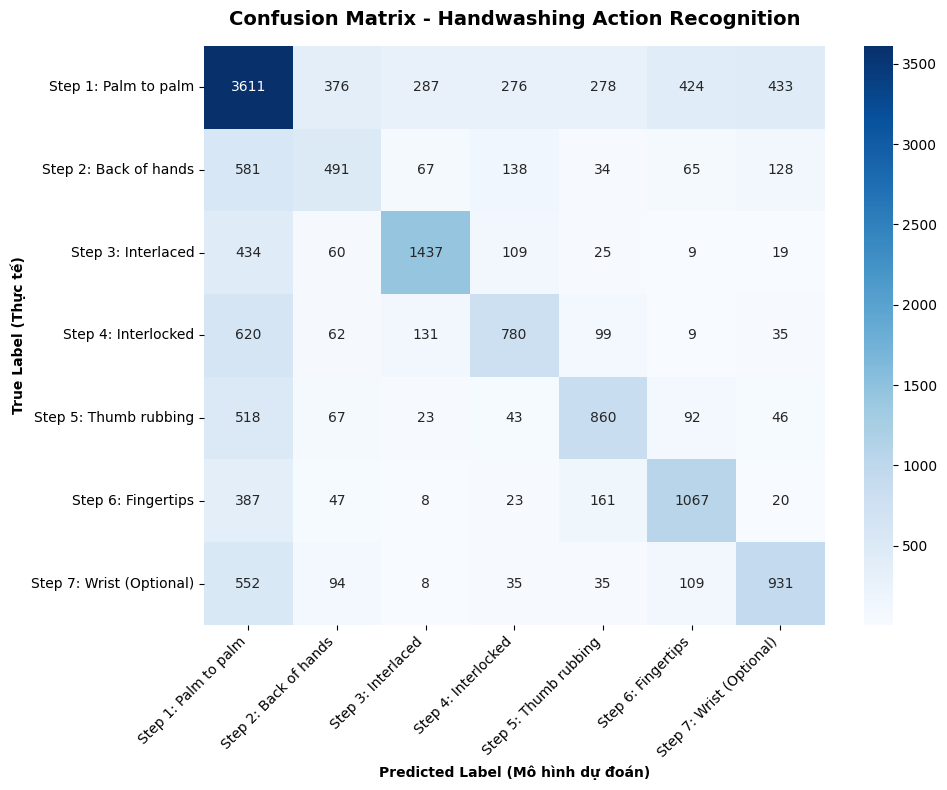

In [32]:
# ==========================================
# 3. VẼ MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
# ==========================================
# Tính ma trận
cm = confusion_matrix(y_test_true, y_pred)

# Khai báo tên 7 bước rửa tay của WHO để biểu đồ hiển thị đẹp hơn
# Nếu nhãn của bạn bắt đầu từ 0 đến 6:
who_steps = [
    "Step 1: Palm to palm",
    "Step 2: Back of hands",
    "Step 3: Interlaced",
    "Step 4: Interlocked",
    "Step 5: Thumb rubbing",
    "Step 6: Fingertips",
    "Step 7: Wrist (Optional)" # Thay bằng nhãn thực tế nếu class thứ 7 của bạn khác
]

# Cấu hình biểu đồ
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True,        # Hiển thị số lượng bên trong từng ô
    fmt='d',           # Định dạng số nguyên (không có dấu thập phân)
    cmap='Blues',      # Tone màu xanh dương dễ nhìn
    xticklabels=who_steps, 
    yticklabels=who_steps
)

# Xoay nhãn trục X để không bị chữ đè lên nhau
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.xlabel('Predicted Label (Mô hình dự đoán)', fontweight='bold')
plt.ylabel('True Label (Thực tế)', fontweight='bold')
plt.title('Confusion Matrix - Handwashing Action Recognition', fontsize=14, fontweight='bold', pad=15)

# Lưu ảnh ra Kaggle working directory và hiển thị
plt.tight_layout()
plt.savefig('/kaggle/working/confusion_matrix_GRU_location.png', dpi=300)
plt.show()